# 03 · Phase I results: from forecast runs to the answers on the dashboard

PRs #13 and #14 · sessions **B1** and **B2** in the AI log · Pair 1, AI-aided

The question pages of the [dashboard](https://sandromueller01.github.io/ai-vis-lab-2026/) read their numbers
from `site/data/results.json`, built by `build_results_data.py` from 336 TiRex-2 runs × 378 points. This
notebook loads the same file, re-draws the key evidence for Q1–Q5, and replays the two corrections that
were made after looking at the output.

**How to read this notebook.** Each step starts with an *AI collaboration* box: what Sandro asked
(reconstructed from the PR description, not a verbatim quote), what the AI assistant proposed, how
it was checked by a human, and what was decided. The code below the box re-computes the evidence from
the repo, so the decision can be checked rather than believed. The full log is in
[`ai-interactions/phase1-ai-aided-pair.md`](../ai-interactions/phase1-ai-aided-pair.md).

In [1]:
from pathlib import Path
import json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "data_acquisition").is_dir() and (p / "README.md").exists():
            return p
    raise FileNotFoundError("run this notebook inside the ai-vis-lab-2026 repo")

ROOT = repo_root()
DATA = ROOT / "data" / "austria_15km"
SITE = ROOT / "phase1-model-behavior" / "pair-1" / "dashboard" / "site" / "data"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.width", 140)
print("repo:", ROOT.name, "| 15 km data present:", (DATA / "grid_long.parquet").exists())

repo: ai-vis-lab-2026 | 15 km data present: True


In [2]:
R = json.loads((SITE / "results.json").read_text())
s = R["summary"]
print(f"{s['n_runs']} start times ({s['n_spread']} spread over the year + {s['n_front_runs']} before cold fronts) x {s['n_points']} points")

336 start times (306 spread over the year + 30 before cold fronts) x 378 points


## Step 1 · Forecast design, and the 304 → 306 correction

> **AI collaboration · B2 · forecast runs**
>
> | | |
> |---|---|
> | **Prompt** *(reconstructed)* | Run TiRex-2 at start times spread over the year and before cold fronts on all 378 points, temperature history only. |
> | **AI proposal** | <code>run_forecasts.py</code>: every 10 days at 9 start hours, plus 6 and 12 h before each cold front; 28 days of context, 24 h ahead, 9 quantiles. |
> | **Human check** | Checked the count against the design: the first texts said 304 spread start times, but the design gives 306. |
> | **Decision** | Corrected to 306 (+ 30 front runs = 336). |

In [3]:
sys.path.insert(0, str(ROOT / "phase1-model-behavior" / "pair-1"))
import run_forecasts as rf
times = pd.read_parquet(DATA / "grid_long.parquet", columns=["time"]).time.drop_duplicates().sort_values()
times = pd.DatetimeIndex(times)
fronts = pd.read_csv(DATA / "fronts.csv", parse_dates=["peak_time"])
starts = rf.start_times(times, fronts, context=672, horizon=24, step_days=10)
tags = pd.Series([t for _, t in starts]).value_counts()
n_days = len(pd.date_range(times[0] + pd.Timedelta(days=29), times[-1] - pd.Timedelta(days=2), freq="10D"))
print(f"{n_days} start days x {len(rf.START_HOURS)} start hours = {n_days * len(rf.START_HOURS)} spread start times")
print(tags.to_dict(), "->", len(starts), "in total; results.json says", s["n_runs"])
print(f"{(fronts.cold_front).sum()} cold fronts, but the first has < 28 days of history -> {tags.get('front-12', 0)} x 2 front runs")

34 start days x 9 start hours = 306 spread start times
{'grid': 306, 'front-12': 15, 'front-6': 15} -> 336 in total; results.json says 336
16 cold fronts, but the first has < 28 days of history -> 15 x 2 front runs


## Q1 · How often is the system wrong?

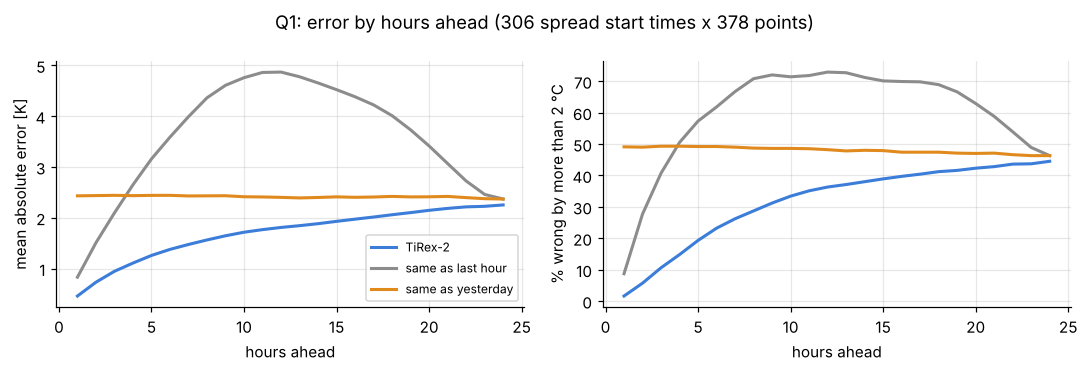

wrong by > 2 °C: 22 % up to 12 h, 41 % at 13-24 h; better than 'same as yesterday' by 81 % at 1 h, 25 % at 12 h, 5 % at 24 h


In [4]:
L = R["lead"]; leads = L["leads"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
names = {"tirex": ("TiRex-2", "#3b7dd8"), "last_hour": ("same as last hour", "0.55"), "yesterday": ("same as yesterday", "#e08a1e")}
for key, (name, c) in names.items():
    axes[0].plot(leads, L["mae"][key], label=name, color=c, lw=2)
    axes[1].plot(leads, L["wrong"][key], label=name, color=c, lw=2)
axes[0].set_ylabel("mean absolute error [K]"); axes[1].set_ylabel("% wrong by more than 2 °C")
for ax in axes: ax.set_xlabel("hours ahead")
axes[0].legend(fontsize=8); fig.suptitle("Q1: error by hours ahead (306 spread start times x 378 points)")
plt.tight_layout(); plt.show()
print(f"wrong by > 2 °C: {s['wrong12']:.0f} % up to 12 h, {s['wrong24']:.0f} % at 13-24 h; "
      f"better than 'same as yesterday' by {s['improve1']:.0f} % at 1 h, {s['improve12']:.0f} % at 12 h, {s['improve24']:.0f} % at 24 h")

## Q2 / Q4 · In which situations is it right or wrong, and is the band honest?

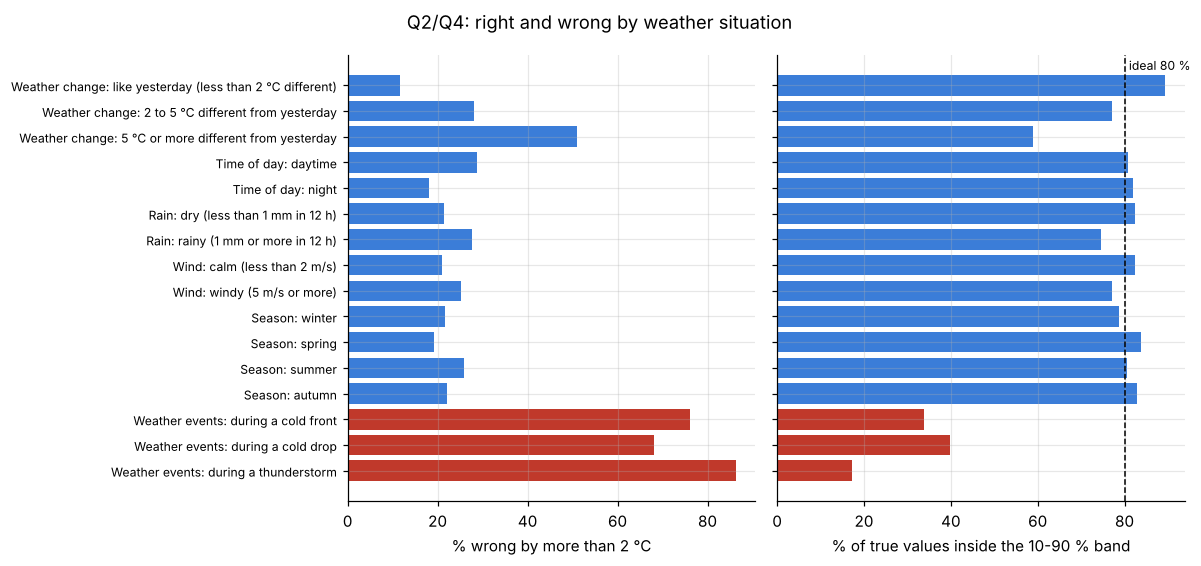

band coverage: 81 % overall, 34 % during cold fronts


,label,% of mistakes that are too warm,n_wrong
0,all situations,43.2,307897
1,daytime,37.8,155036
2,night,48.6,152861
3,during a cold front,99.3,11485
4,during a cold drop,96.7,11748
5,during a thunderstorm,99.9,1651


In [5]:
sit = pd.DataFrame(R["situations"])
sit["name"] = sit.group + ": " + sit.label
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True)
y = np.arange(len(sit))
axes[0].barh(y, sit.wrong, color=np.where(sit.group == "Weather events", "#c0392b", "#3b7dd8"))
axes[1].barh(y, sit.cover, color=np.where(sit.group == "Weather events", "#c0392b", "#3b7dd8"))
axes[1].axvline(80, color="black", ls="--", lw=1); axes[1].text(81, -0.6, "ideal 80 %", fontsize=8)
axes[0].set_yticks(y, sit.name, fontsize=8); axes[0].invert_yaxis()
axes[0].set_xlabel("% wrong by more than 2 °C"); axes[1].set_xlabel("% of true values inside the 10-90 % band")
fig.suptitle("Q2/Q4: right and wrong by weather situation"); plt.tight_layout(); plt.show()
print(f"band coverage: {s['cover']:.0f} % overall, "
      f"{sit.set_index('label').loc['during a cold front', 'cover']:.0f} % during cold fronts")
pd.DataFrame(R["mistakes"]).rename(columns={"too_warm": "% of mistakes that are too warm"})

The pattern from the smoke test (notebook 01) is now systematic: in normal weather the band is close to
honest (≈ 81 %), during cold fronts it holds the truth only about a third of the time, and almost all
mistakes during events are **too warm**: the model keeps the old air mass.

## Q5 · What happens around the arrival of a front?

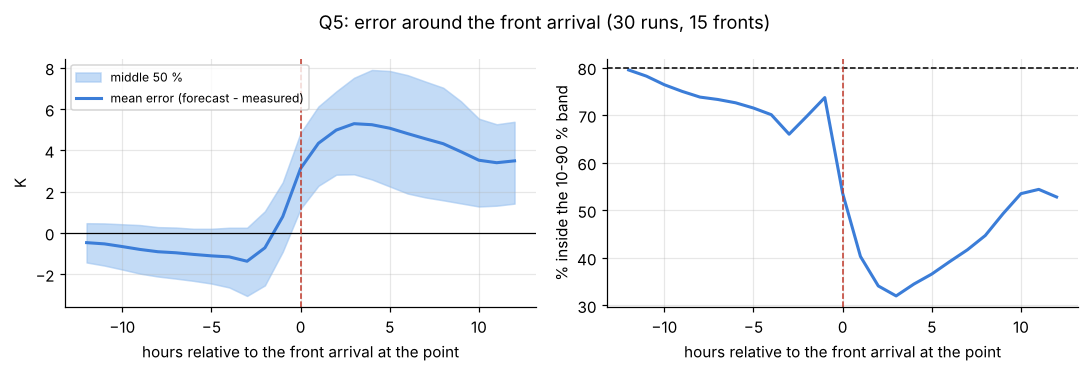

before the front (-6..-3 h): -1.2 K (too cold); 3 h after: +5.3 K (too warm); coverage at +3 h: 32 %


In [6]:
F = R["front_error"]; rel = np.array(F["rel"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].fill_between(rel, F["q25"], F["q75"], color="#9cc3f0", alpha=0.6, label="middle 50 %")
axes[0].plot(rel, F["mean"], color="#3b7dd8", lw=2, label="mean error (forecast - measured)")
axes[0].axhline(0, color="black", lw=0.8); axes[0].axvline(0, color="#c0392b", ls="--", lw=1)
axes[0].set_ylabel("K"); axes[0].legend(fontsize=8)
axes[1].plot(rel, F["cover"], color="#3b7dd8", lw=2); axes[1].axhline(80, color="black", ls="--", lw=1)
axes[1].axvline(0, color="#c0392b", ls="--", lw=1); axes[1].set_ylabel("% inside the 10-90 % band")
for ax in axes: ax.set_xlabel("hours relative to the front arrival at the point")
fig.suptitle(f"Q5: error around the front arrival ({F['runs']} runs, {F['fronts']} fronts)")
plt.tight_layout(); plt.show()
fe = pd.Series(F["mean"], index=rel)
print(f"before the front (-6..-3 h): {fe.loc[-6:-3].mean():+.1f} K (too cold); "
      f"3 h after: {fe.loc[3]:+.1f} K (too warm); coverage at +3 h: {pd.Series(F['cover'], index=rel).loc[3]:.0f} %")

## Step 2 · The jump-to buttons: a correct number that was wrong for the reader

> **AI collaboration · B1 · explore dashboard**
>
> | | |
> |---|---|
> | **Prompt** *(reconstructed)* | Add 'Jump to' buttons that open the three largest cold fronts on the map. |
> | **AI proposal** | Jump to the <code>peak_time</code> of each front in <code>fronts.csv</code> (the hour with the highest share of passages within ±12 h). |
> | **Human check** | Opened the map at those hours: almost no point was marked, because a front needs about 12 h to cross Austria and the peak of a ±12 h window is not the hour when most points are in the passage. |
> | **Decision** | Modified: jump to the hour in which most points are in the passage. |

In [7]:
cf = pd.read_parquet(DATA / "events.parquet", columns=["point_id", "time", "kind"])
cf = cf[cf.kind == "cold_front"]
in_passage = cf.groupby("time").point_id.nunique() / s["n_points"] * 100
rows = []
for _, f in fronts[fronts.cold_front].nlargest(3, "share").iterrows():
    w = in_passage.loc[f.peak_time - pd.Timedelta("12h"): f.peak_time + pd.Timedelta("12h")]
    rows.append({"front": f"{f.peak_time:%d %b %Y}", "peak_time (AI)": f"{f.peak_time:%H} UTC",
                 "% points marked then": round(in_passage.get(f.peak_time, 0), 1),
                 "best hour (fix)": f"{w.idxmax():%d %b %H} UTC", "% points marked at best hour": round(w.max(), 1)})
pd.DataFrame(rows)

,front,peak_time (AI),% points marked then,best hour (fix),% points marked at best hour
0,11 May 2026,21 UTC,0.0,12 May 07 UTC,96.8
1,01 Jul 2026,06 UTC,0.8,01 Jul 14 UTC,69.6
2,25 Mar 2026,22 UTC,18.3,26 Mar 09 UTC,77.2


## Q5 · Where, and with how many neighbours?

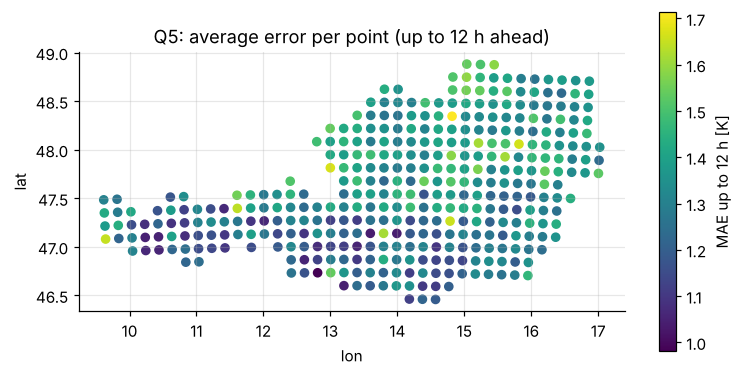

,name,n,mae,bias
0,"West (Vorarlberg, Tyrol)",52,1.25,-0.13
1,"Centre (Salzburg, Carinthia, Styria)",163,1.30,-0.17
2,"East (Upper and Lower Austria, Vienna, Burgenl...",163,1.36,-0.09


,neighbours,n,mae
0,1,4,1.40
1,2,34,1.35
2,3,58,1.30
3,4,282,1.32


In [8]:
pts = pd.DataFrame(R["points"])
fig, ax = plt.subplots(figsize=(8, 4))
sc = ax.scatter(pts.lon, pts.lat, c=pts.mae12, cmap="viridis", s=28)
plt.colorbar(sc, label="MAE up to 12 h [K]"); ax.set_aspect(1.45)
ax.set_title("Q5: average error per point (up to 12 h ahead)"); ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.show()
display(pd.DataFrame(R["regions"]).round(2))
pd.DataFrame(R["neighbour_stats"]).round(2)

## Summary: from prompts to results

| Result on the dashboard | Came from | Human part |
|---|---|---|
| TiRex-2 is overconfident at events (band 34 % at cold fronts) | smoke test metric (A4) → spread and front runs (B2) | noticed it in the smoke test; made it a main thread |
| Forecast too warm after a front (+5.3 K at 3 h) | literature-based front label (A6) + error around arrival (B2) | checked the label on calm days, big events, wind and rain |
| Temperature history only as input | synthetic covariate check (A4) | kept the upstream idea as a team decision |
| 336 runs = 306 + 30 | `run_forecasts.py` (B2) | caught the 304 vs 306 mismatch |
| Jump-to hours, day/hour slider, dark-only page | dashboard (B1) | found by looking at the page and in Carlos's review |

The AI did most of the typing: code, data formats, texts. The decisions that shaped the results —
reacting to the flat covariate result, insisting on a front definition that says *when*, and reproducing
known numbers before trusting a pipeline — were made by checking its output against the data.